In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def execute_and_plot(circuit, shots):
    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)


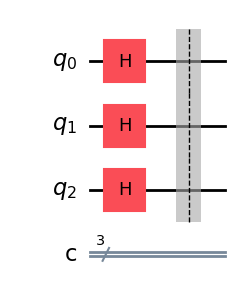

In [2]:
circuit = QuantumCircuit(3, 3)

# Initialize all qubits to state of superposition
circuit.h(0)
circuit.h(1)
circuit.h(2)

circuit.barrier()

circuit.draw(output='mpl')

In [3]:
# Grover's Algorithm (repeat O(sqrt(n)))
# Apply Oracle for state 110
circuit.x(0)
circuit.h(2)
circuit.ccx(0,1,2)
circuit.h(2)
circuit.x(0)

circuit.barrier()

# Perform the Grover's diffusion operator
circuit.h(0)
circuit.h(1)
circuit.h(2)

circuit.x(0)
circuit.x(1)
circuit.x(2)

circuit.h(2)
circuit.ccx(0,1,2)
circuit.h(2)

circuit.x(0)
circuit.x(1)
circuit.x(2)

circuit.h(0)
circuit.h(1)
circuit.h(2)

circuit.barrier()

CircuitInstruction(operation=Instruction(name='barrier', num_qubits=3, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q"), index=0>, <Qubit register=(3, "q"), index=1>, <Qubit register=(3, "q"), index=2>), clbits=())

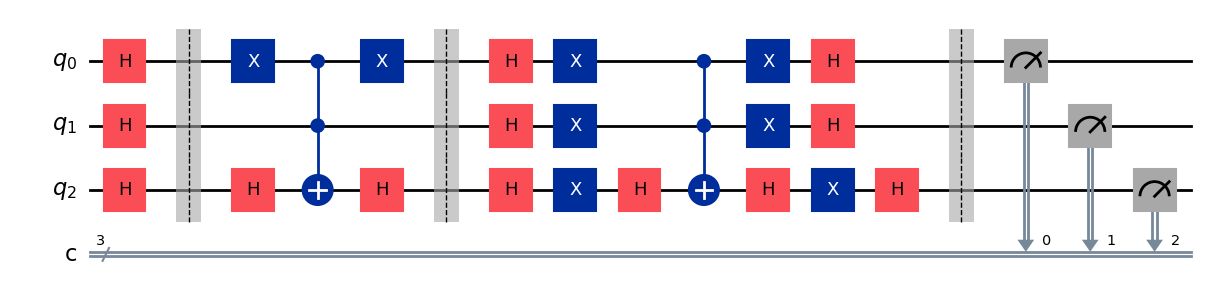

In [4]:
# Measure the output
circuit.measure(0,0)
circuit.measure(1,1)
circuit.measure(2,2)

circuit.draw(output='mpl')

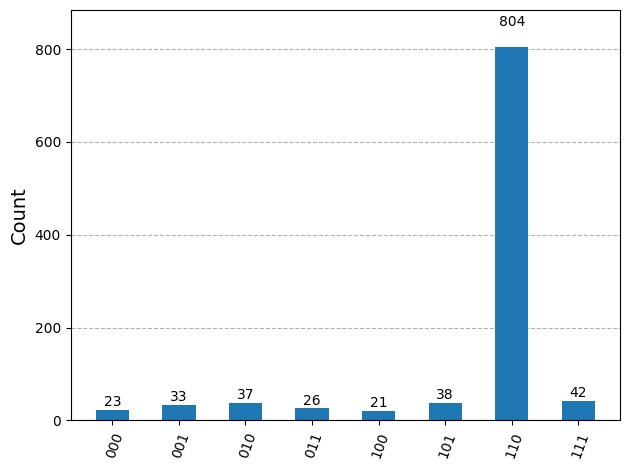

In [5]:
execute_and_plot(circuit, 1024)

In [ ]:
# Note that 110 is the highest probability measured state which gives us the answer